## AIM: Coding Attention Mechanism 

## DOB: 27-10-2026

## Author: Shalu Singh

## We will implement 4 different varients of attention mechansim

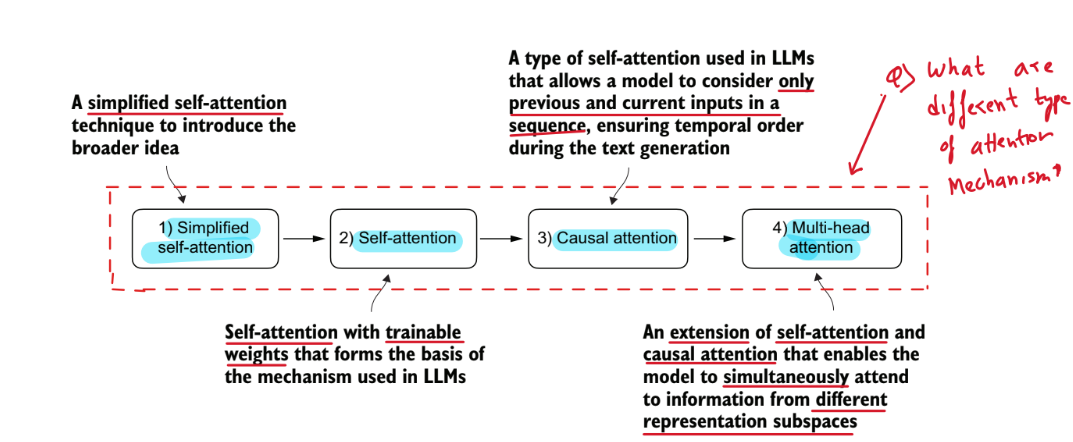


### 1) Simple Self Attention

- Here we will implement self-attention without **trainable weights**

#### Q1) What is the goal of self-attention ?

Ans) The goal of self-attention is to compute the **context vector** for each input element in the  input sentence.

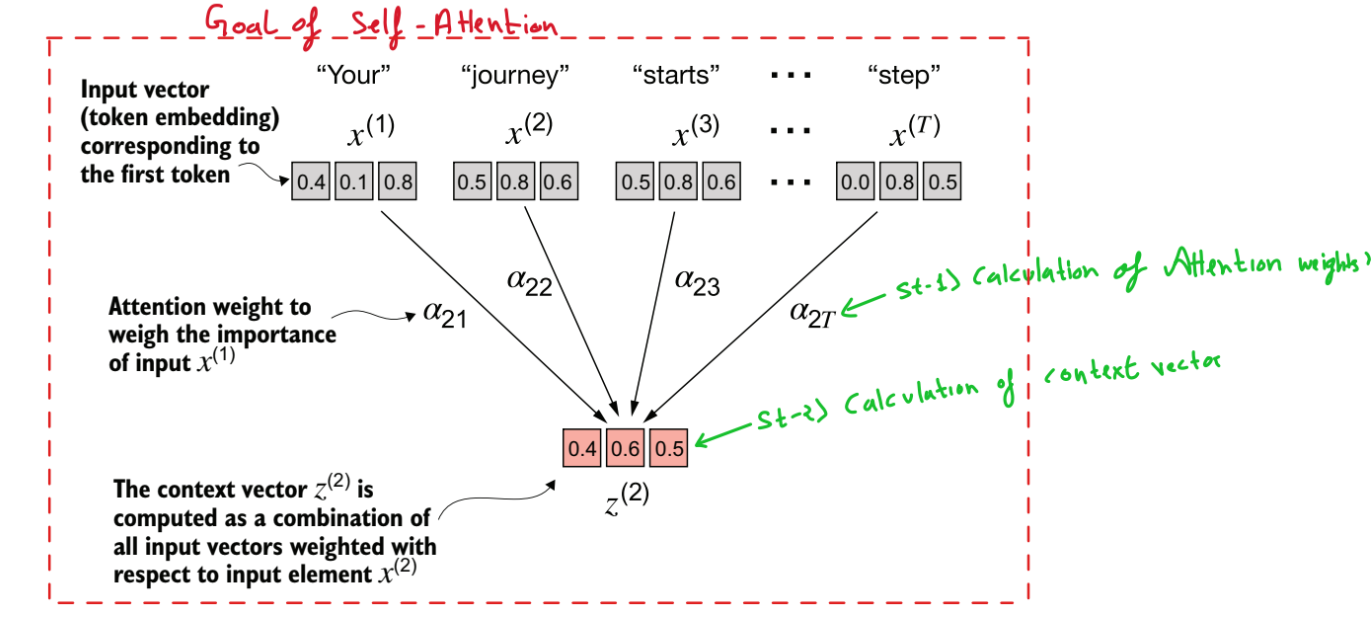



### Q.2) What is a Context Vector?

**Answer:**

1. A context vector is a representation of a token that contains **information about the token itself as well as its surrounding context in the input sequence**.

2. Unlike a basic embedding, which represents a token without considering the other tokens in the current input sequence, a context vector is **enriched embedding vector**.

---

**Example:**

Consider the sentence:

> "The animal didn't cross the street because it was tired."

The meaning of the word *"it"* depends on the surrounding words. A context-aware representation can incorporate information from the sentence to help the model understand what *"it"* refers to.

---

**💡 Key Takeaway**

> An embedding represents a token, while a context vector represents a token enriched with information from its context.

### Q.3) What Are the Algorithmic Steps to Calculate the Context Vector?

**Answer:**

1. **Compute the Attention Scores**
2. **Compute the Attention Weights**
3. **Compute the Context Vector**

---

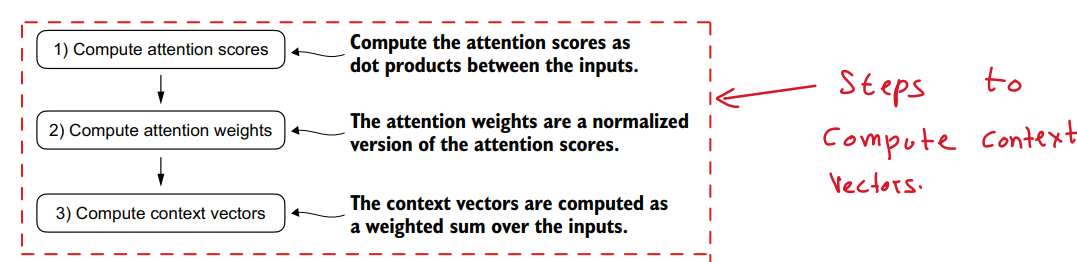

In [3]:
# Input sentence

import torch
inputs = torch.tensor(
 [[0.43, 0.15, 0.89], # Your (x^1)
 [0.55, 0.87, 0.66], # journey (x^2)
 [0.57, 0.85, 0.64], # starts (x^3)
 [0.22, 0.58, 0.33], # with (x^4)
 [0.77, 0.25, 0.10], # one (x^5)
 [0.05, 0.80, 0.55]]) # step (x^6)

print(inputs.shape)

torch.Size([6, 3])


### 1. Computation of Attention Scores

**Answer:**

The computation of attention scores involves the following steps:

1. **Dot Product of Query and Key Vectors:** Calculate the dot product between each token's **Query vector and every token's Key vector**, including its own. This determines how relevant each token is to the token being processed.

   Mathematically,

   $$
   s_{ij} = \mathbf{q}_i \cdot \mathbf{k}_j
   $$

   Where:
   - $s_{ij}$ = Attention score between query token $i$ and key token $j$
   - $\mathbf{q}_i$ = Query vector of token $i$
   - $\mathbf{k}_j$ = Key vector of token $j$
   - $\cdot$ = Dot product operation

2. **Shape of the Attention Score Matrix:** The attention score matrix is a square matrix with dimensions **n × n**, where **n** is the number of tokens in the input sequence.

   Mathematically,

   $$
   \mathbf{S} \in \mathbb{R}^{n \times n}
   $$

3. **Dot Product as a Measure of Similarity:** The dot product measures how closely two vectors are aligned. A higher dot product indicates a greater degree of alignment or similarity between the vectors.

4. **Role in Self-Attention:** In self-attention, the dot product determines how much attention each token should pay to every other token in the input sequence.

---

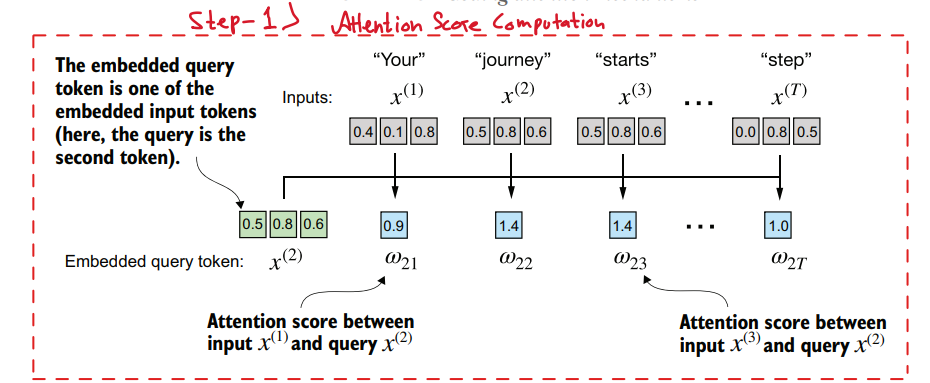

In [4]:
# Example: computing attention score of 'journey' with respect to all input embeddings

query = inputs[1] # journey
attention_score_2 = torch.empty(size = (inputs.shape[0],)) # size = total inputs in a sentence
for idx,ip in enumerate(inputs):
    attention_score_2[idx] = torch.dot(query,inputs[idx]) # = query @ inputs[idx]

print(attention_score_2)

tensor([0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865])


### 2. Computation of Attention Weights

**Answer:**

1. **Normalization of Attention Scores:** Attention weight computation basically means normalizing the attention scores.

2. **Goal of Normalization:** The main goal of normalization is to obtain attention scores that sum up to 1. This is useful for interpretation and managing training stability in LLMs.

   Mathematically, for each query token $i$:

   $$
   \sum_{j=1}^{n} \alpha_{ij} = 1
   $$

   Where:
   - $\alpha_{ij}$ = Attention weight assigned by query token $i$ to key token $j$
   - $n$ = Total number of tokens in the input sequence

3. **Direction of Normalization:** Normalization is performed across each row of the attention score matrix in the standard self-attention formulation.

   - **Why row-wise normalization?** Each row represents the attention scores of one query token against all key tokens in the input sequence. Applying softmax across the row converts these scores into attention weights that sum up to 1, indicating how much attention the query token assigns to each key token.

   The attention weights are calculated using the softmax function:

   $$
   \alpha_{ij} = \frac{e^{s_{ij}}}{\sum_{k=1}^{n} e^{s_{ik}}}
   $$

   Where:
   - $s_{ij}$ = Attention score between query token $i$ and key token $j$
   - $e$ = Base of the natural exponential function
   - $n$ = Total number of tokens in the input sequence

---

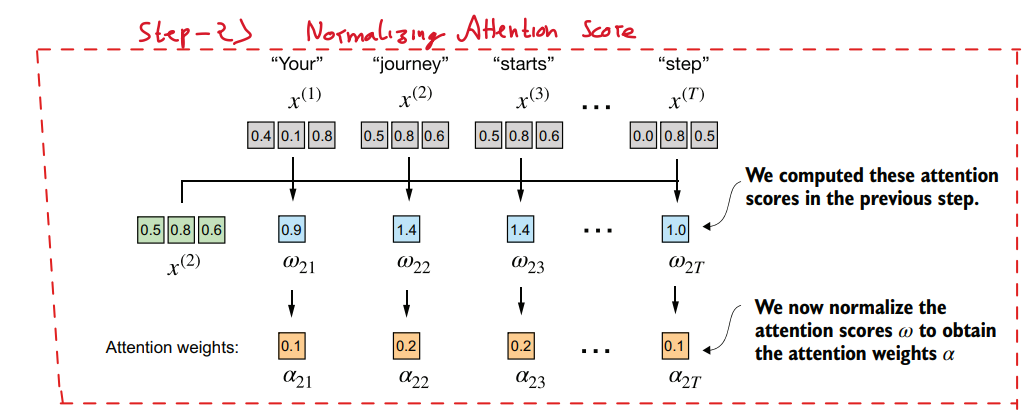

In [5]:
# Example: Computation of attention weight for query 2 i.e. journey
attention_weight_2 = torch.softmax(attention_score_2,dim = 0) # softmax normalization
print(attention_weight_2)
print(attention_weight_2.sum())

tensor([0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581])
tensor(1.)


### 3. Computation of Context Vector

**Answer:**

1. **Weighted Sum of Input Vectors:** A context vector is the weighted sum of all input vectors, obtained by multiplying each input vector by its corresponding attention weight.

   Mathematically,

   $$ 
   \mathbf{z}_i = \sum_{j=1}^{n} \alpha_{ij} \mathbf{x}_j
   $$

   Where:

   - $\mathbf{z}_i$ = Context vector for token $i$
   - $\alpha_{ij}$ = Attention weight assigned by token $i$ to token $j$
   - $\mathbf{x}_j$ = Input vector of token $j$
   - $n$ = Total number of tokens in the input sequence

2. **Shape of the Context Vector:** Its shape is the same as the input vector.

   If each input vector has dimension $d$, then:

   $$
   \mathbf{x}_j \in \mathbb{R}^{d}
   \quad \Rightarrow \quad
   \mathbf{z}_i \in \mathbb{R}^{d}
   $$


---

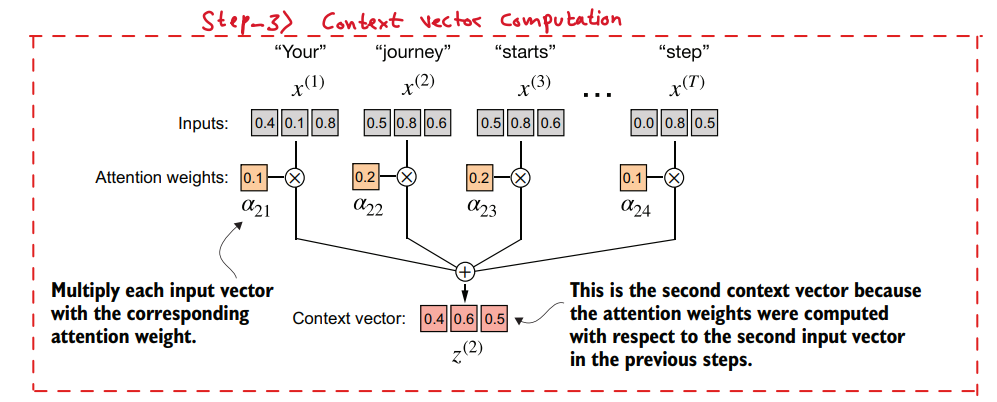

In [6]:
# Example: Computing context vector for query 2

context_vector_2 = torch.zeros(query.shape)


for idx,_ in enumerate(inputs):
    context_vector_2 += attention_weight_2[idx] * inputs[idx]   # weighted sum

context_vector_2

tensor([0.4419, 0.6515, 0.5683])

### General Formula for Computation of Context Vector

#### 1. Computing Attention Scores

Consider an input sequence consisting of **6 tokens**, where each token has an embedding dimension of **3**.

Therefore, the input matrix has a shape of $(6, 3)$.

In self-attention, the input matrix is transformed into three matrices: **Query (Q), Key (K), and Value (V)**.

Assuming the Query and Key dimensions are 3:

$$
Q = XW_Q, \qquad K = XW_K, \qquad V = XW_V
$$

For simplicity, assume all three matrices have a shape of $(6, 3)$.

**Matrix shapes:**

$$
\boxed{
\underbrace{X}_{6 \times 3}
\quad
\underbrace{W_Q}_{3 \times 3}
\quad \Longrightarrow \quad
\underbrace{Q}_{6 \times 3}
}
$$

Similarly, $K$ and $V$ also have shapes of $(6, 3)$.

The attention score matrix is computed by multiplying the Query matrix by the transpose of the Key matrix:

$$
S = QK^T
$$

$$
\underbrace{Q}_{6 \times 3}
\ @ \
\underbrace{K^T}_{3 \times 6}
\ = \
\underbrace{S}_{6 \times 6}
$$

The resulting attention score matrix has a shape of $(6, 6)$ because it contains one score for every query-key token pair.

---

#### 2. Computing Attention Weights

Attention weights are computed by applying the **softmax function row-wise** to the attention score matrix.

$$
A = \operatorname{softmax}(S)
$$

$$
\underbrace{S}_{6 \times 6}
\quad \xrightarrow{\text{Row-wise Softmax}} \quad
\underbrace{A}_{6 \times 6}
$$

Each row of the attention weight matrix sums to 1:

$$
\sum_{j=1}^{6} A_{ij} = 1
$$

Each row represents how a particular query token distributes its attention across all six key tokens.

---

#### 3. Computing Context Vectors

The context vector matrix is calculated by multiplying the attention weight matrix by the Value matrix.

$$
C = AV
$$

$$
\underbrace{A}_{6 \times 6}
\ @ \
\underbrace{V}_{6 \times 3}
\ = \
\underbrace{C}_{6 \times 3}
$$

The resulting context vector matrix has a shape of $(6, 3)$, which is the same as the Value matrix shape.

Each row of $C$ represents the context vector for one token, computed as the weighted sum of all Value vectors using that token's attention weights.

---

### Summary of Matrix Shapes

| Matrix | Description | Shape |
|---|---|---|
| $X$ | Input embedding matrix | $(6, 3)$ |
| $Q$ | Query matrix | $(6, 3)$ |
| $K$ | Key matrix | $(6, 3)$ |
| $V$ | Value matrix | $(6, 3)$ |
| $K^T$ | Transpose of Key matrix | $(3, 6)$ |
| $S = QK^T$ | Attention score matrix | $(6, 6)$ |
| $A = \operatorname{softmax}(S)$ | Attention weight matrix | $(6, 6)$ |
| $C = AV$ | Context vector matrix | $(6, 3)$ |

---


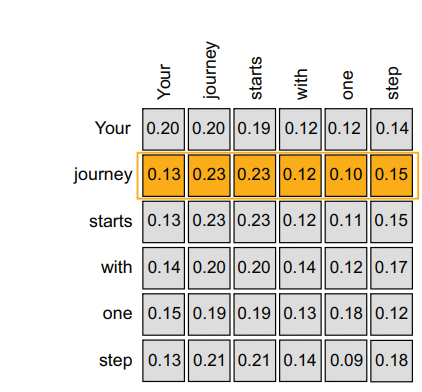

In [7]:
# 1) Computing attention score

# For simplicity consider inputs as Query,Key and Value vector
Query = inputs
Key = inputs
Value = inputs

# computing attention score
att_score = Query @ Key.T     # matrix multiplication
att_score.shape,att_score

(torch.Size([6, 6]),
 tensor([[0.9995, 0.9544, 0.9422, 0.4753, 0.4576, 0.6310],
         [0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865],
         [0.9422, 1.4754, 1.4570, 0.8296, 0.7154, 1.0605],
         [0.4753, 0.8434, 0.8296, 0.4937, 0.3474, 0.6565],
         [0.4576, 0.7070, 0.7154, 0.3474, 0.6654, 0.2935],
         [0.6310, 1.0865, 1.0605, 0.6565, 0.2935, 0.9450]]))

In [8]:
# 2) Computing attentin weight

att_weight = torch.softmax(att_score,dim = -1)  # normalizing along the rows 
att_weight.shape,att_weight.sum(-1) # sum along each row
print(att_weight)

tensor([[0.2098, 0.2006, 0.1981, 0.1242, 0.1220, 0.1452],
        [0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581],
        [0.1390, 0.2369, 0.2326, 0.1242, 0.1108, 0.1565],
        [0.1435, 0.2074, 0.2046, 0.1462, 0.1263, 0.1720],
        [0.1526, 0.1958, 0.1975, 0.1367, 0.1879, 0.1295],
        [0.1385, 0.2184, 0.2128, 0.1420, 0.0988, 0.1896]])


In [9]:
# 3) Computing Context vector

context_vector = att_weight @ Value # Matrix Multiplicatoin
context_vector  # each row in the context vector matrix represent contex vector of each token at it's position 

tensor([[0.4421, 0.5931, 0.5790],
        [0.4419, 0.6515, 0.5683],
        [0.4431, 0.6496, 0.5671],
        [0.4304, 0.6298, 0.5510],
        [0.4671, 0.5910, 0.5266],
        [0.4177, 0.6503, 0.5645]])

## Implementing self-attention with trainable weights

### Q.4) Why Do We Need Trainable Weight Matrices in Self-Attention?

**Answer:**

1. **Learning Good Context Vectors:** Trainable weight matrices are crucial because they allow the model to learn how to produce **good context vectors** by learning meaningful Query, Key, and Value representations from the input embeddings.

---

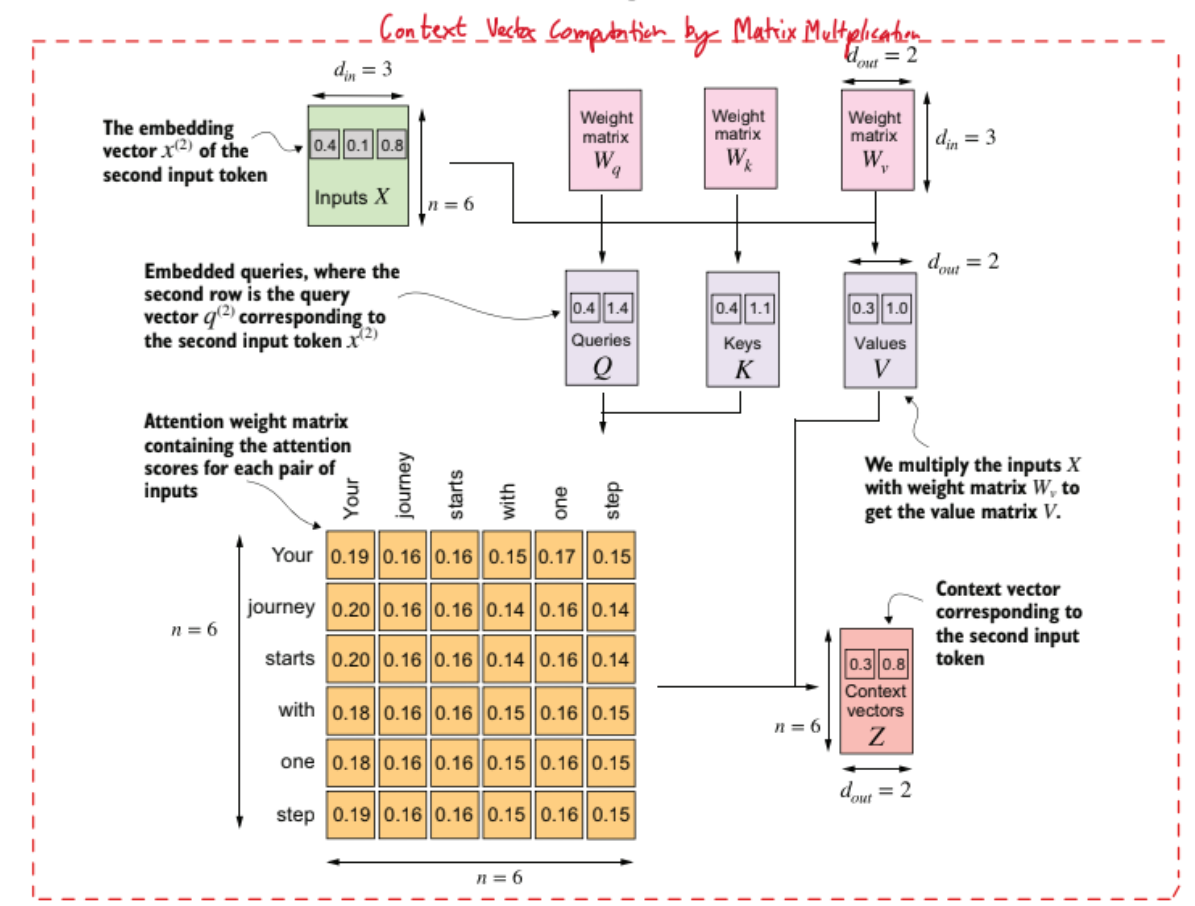

#### Implementing a compact self-attention class `selfAttention_v1`

In [10]:
# selfAttention_v1 class

class selfAttention_v1(torch.nn.Module):
    def __init__(self,d_in,d_out):
        super().__init__()
        self.W_query = torch.nn.Parameter(torch.rand(d_in,d_out))
        self.W_key = torch.nn.Parameter(torch.rand(d_in,d_out))
        self.W_value = torch.nn.Parameter(torch.rand(d_in,d_out))

    def forward(self,x):
        query = x @ self.W_query
        key = x @ self.W_key
        value = x @ self.W_value

        # Step-1) Attention score
        att_score = query @ key.T   
        # Step-2) Attention weight
        att_weight = torch.softmax(att_score / key.shape[-1] ** 0.5,dim = -1)  # scaled normalization
        # Step-3) Context vector
        context_vectors = att_weight @ value
        return context_vectors

In [11]:
# calling selfAttention_v1 class
torch.manual_seed(123)
d_in = 3
d_out = 2
sa_v1 = selfAttention_v1(d_in,d_out)
context_vec1 = sa_v1(inputs)
context_vec1

tensor([[0.2996, 0.8053],
        [0.3061, 0.8210],
        [0.3058, 0.8203],
        [0.2948, 0.7939],
        [0.2927, 0.7891],
        [0.2990, 0.8040]], grad_fn=<MmBackward0>)

### Q.5) Why Do We Need to Scale the Dot Product While Computing Attention Weights?

**Answer:**

1. **Improving Training Stability:** We scale the dot product to prevent the softmax function from producing extremely small gradients, which can slow down learning during backpropagation.

2. **Effect of Large Embedding Dimensions:** When the dimensions of Query and Key vectors are large, their dot products can become large in magnitude. This can cause the softmax function to produce attention weights that are close to 0 or 1.

3. **Effect on Gradients:** When softmax outputs are close to 0 or 1, its gradients can become very small. As a result, the model may learn slowly because the weight matrices receive weaker gradient updates.

4. **Scaling by the Square Root of the Dimension:** To reduce this problem, we divide the Query-Key dot product by the square root of the key vector dimension. This mechanism is called **Scaled Dot-Product Attention**.

   **Formula:**

   $$
   \text{Attention Scores} = \frac{QK^T}{\sqrt{d_k}}
   $$

   Where:
   - $Q$ = Query matrix
   - $K^T$ = Transpose of the Key matrix
   - $d_k$ = Dimension of each Key vector
   - $\sqrt{d_k}$ = Scaling factor

   The scaled attention scores are then passed through softmax to obtain the attention weights:

   $$
   A = \operatorname{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)
   $$

**Key Takeaway:** Scaling keeps attention scores at a more manageable magnitude, helping softmax avoid saturation and allowing gradients to flow more effectively during training.


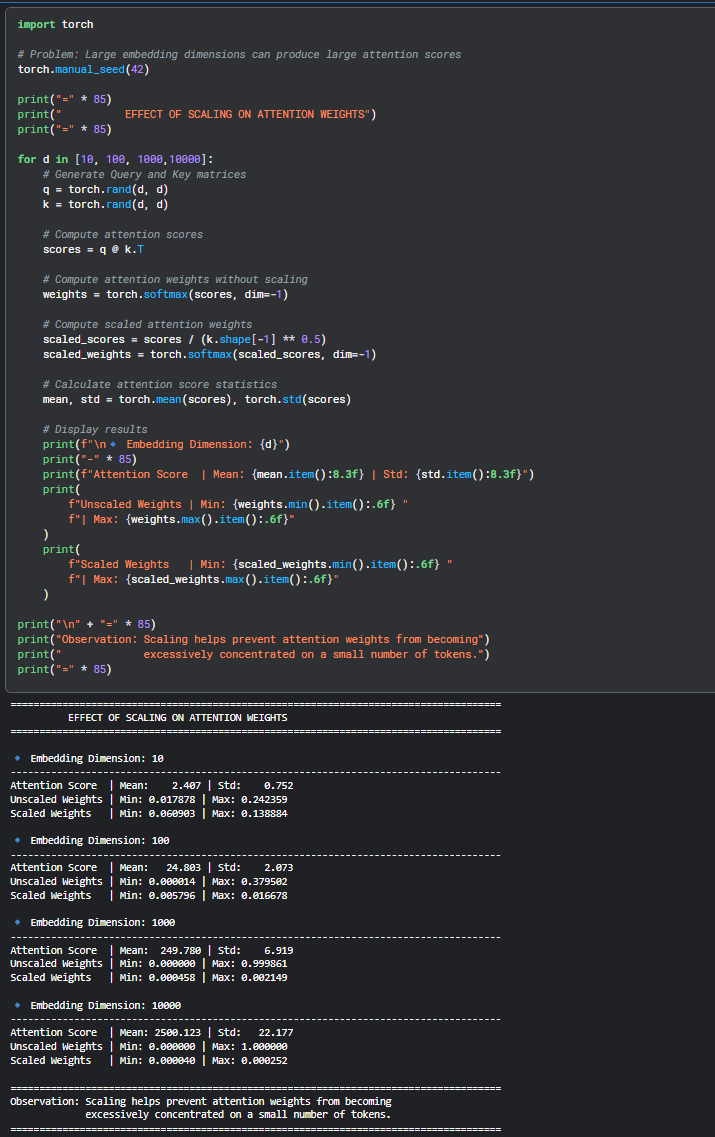

In [12]:
import torch

# Problem: Large embedding dimensions can produce large attention scores
torch.manual_seed(42)

print("=" * 85)
print("          EFFECT OF SCALING ON ATTENTION WEIGHTS")
print("=" * 85)

for d in [10, 100, 1000,10000]:
    # Generate Query and Key matrices
    q = torch.rand(d, d)
    k = torch.rand(d, d)

    # Compute attention scores
    scores = q @ k.T

    # Compute attention weights without scaling
    weights = torch.softmax(scores, dim=-1)

    # Compute scaled attention weights
    scaled_scores = scores / (k.shape[-1] ** 0.5)
    scaled_weights = torch.softmax(scaled_scores, dim=-1)

    # Calculate attention score statistics
    mean, std = torch.mean(scores), torch.std(scores)

    # Display results
    print(f"\n🔹 Embedding Dimension: {d}")
    print("-" * 85)
    print(f"Attention Score  | Mean: {mean.item():8.3f} | Std: {std.item():8.3f}")
    print(
        f"Unscaled Weights | Min: {weights.min().item():.6f} "
        f"| Max: {weights.max().item():.6f}"
    )
    print(
        f"Scaled Weights   | Min: {scaled_weights.min().item():.6f} "
        f"| Max: {scaled_weights.max().item():.6f}"
    )

print("\n" + "=" * 85)
print("Observation: Scaling helps prevent attention weights from becoming")
print("             excessively concentrated on a small number of tokens.")
print("=" * 85)

          EFFECT OF SCALING ON ATTENTION WEIGHTS

🔹 Embedding Dimension: 10
-------------------------------------------------------------------------------------
Attention Score  | Mean:    2.407 | Std:    0.752
Unscaled Weights | Min: 0.017878 | Max: 0.242359
Scaled Weights   | Min: 0.060903 | Max: 0.138884

🔹 Embedding Dimension: 100
-------------------------------------------------------------------------------------
Attention Score  | Mean:   24.803 | Std:    2.073
Unscaled Weights | Min: 0.000014 | Max: 0.379502
Scaled Weights   | Min: 0.005796 | Max: 0.016678

🔹 Embedding Dimension: 1000
-------------------------------------------------------------------------------------
Attention Score  | Mean:  249.780 | Std:    6.919
Unscaled Weights | Min: 0.000000 | Max: 0.999861
Scaled Weights   | Min: 0.000458 | Max: 0.002149

🔹 Embedding Dimension: 10000
-------------------------------------------------------------------------------------
Attention Score  | Mean: 2500.123 | Std:   22.177

### Implementig self-attention class using `Pytorch Linear Layers`

In [13]:
# selfAttention_v2 class

class selfAttention_v2(torch.nn.Module):
    def __init__(self,d_in,d_out,qkv_bias = False):
        super().__init__()
        self.W_query = torch.nn.Linear(in_features = d_in,out_features = d_out,bias = qkv_bias)
        self.W_key = torch.nn.Linear(in_features = d_in,out_features = d_out,bias = qkv_bias)
        self.W_value = torch.nn.Linear(in_features = d_in,out_features = d_out,bias = qkv_bias)

    def forward(self,x):
        query = self.W_query(x)
        key = self.W_key(x)
        value = self.W_value(x)

        # 1) Attention Score
        att_score = query @ key.T
        # 2) Attention weight
        att_weight = torch.softmax(att_score / key.shape[-1] ** 0.5,dim=-1)
        # 3) Context vector
        context_vector = att_weight @ value
        return context_vector

In [14]:
d_in,d_out

(3, 2)

In [15]:
# calling selfAttention_v2 class
torch.manual_seed(123)
sa_v2 = selfAttention_v2(d_in,d_out)
context_vec2 = sa_v2(inputs)
context_vec2

tensor([[-0.5337, -0.1051],
        [-0.5323, -0.1080],
        [-0.5323, -0.1079],
        [-0.5297, -0.1076],
        [-0.5311, -0.1066],
        [-0.5299, -0.1081]], grad_fn=<MmBackward0>)

---

### 📝 TASK: Transfer Weights Between Self-Attention Implementations

**Objective:** Correctly assign the weights from an instance of `selfAttention_v2` to an instance of `selfAttention_v1`.

**Hint:** `nn.Linear` stores its weight matrix in transposed form relative to the conventional mathematical representation.

---

In [16]:
# selfAttention_v1 instance weights
def display_model_weights():
    print("-"*50)
    print("selfAttention_v1 instance weights:")
    print(dict(sa_v1.named_parameters()))
    print("-"*50)
    
    print("selfAttention_v2 instance weights:")
    print(dict(sa_v2.named_parameters()))
    print("-"*50)

display_model_weights()

--------------------------------------------------
selfAttention_v1 instance weights:
{'W_query': Parameter containing:
tensor([[0.2961, 0.5166],
        [0.2517, 0.6886],
        [0.0740, 0.8665]], requires_grad=True), 'W_key': Parameter containing:
tensor([[0.1366, 0.1025],
        [0.1841, 0.7264],
        [0.3153, 0.6871]], requires_grad=True), 'W_value': Parameter containing:
tensor([[0.0756, 0.1966],
        [0.3164, 0.4017],
        [0.1186, 0.8274]], requires_grad=True)}
--------------------------------------------------
selfAttention_v2 instance weights:
{'W_query.weight': Parameter containing:
tensor([[-0.2354,  0.0191, -0.2867],
        [ 0.2177, -0.4919,  0.4232]], requires_grad=True), 'W_key.weight': Parameter containing:
tensor([[-0.4196, -0.4590, -0.3648],
        [ 0.2615, -0.2133,  0.2161]], requires_grad=True), 'W_value.weight': Parameter containing:
tensor([[-0.4900, -0.3503, -0.2120],
        [-0.1135, -0.4404,  0.3780]], requires_grad=True)}
-----------------------

In [17]:
# assigning sa_v2 weights to sa_v1 weights
with torch.no_grad():
    for sa_v1_w,sa_v2_w in zip(sa_v1.parameters(),sa_v2.parameters()):
        sa_v1_w.copy_(sa_v2_w.T)
  

display_model_weights()

--------------------------------------------------
selfAttention_v1 instance weights:
{'W_query': Parameter containing:
tensor([[-0.2354,  0.2177],
        [ 0.0191, -0.4919],
        [-0.2867,  0.4232]], requires_grad=True), 'W_key': Parameter containing:
tensor([[-0.4196,  0.2615],
        [-0.4590, -0.2133],
        [-0.3648,  0.2161]], requires_grad=True), 'W_value': Parameter containing:
tensor([[-0.4900, -0.1135],
        [-0.3503, -0.4404],
        [-0.2120,  0.3780]], requires_grad=True)}
--------------------------------------------------
selfAttention_v2 instance weights:
{'W_query.weight': Parameter containing:
tensor([[-0.2354,  0.0191, -0.2867],
        [ 0.2177, -0.4919,  0.4232]], requires_grad=True), 'W_key.weight': Parameter containing:
tensor([[-0.4196, -0.4590, -0.3648],
        [ 0.2615, -0.2133,  0.2161]], requires_grad=True), 'W_value.weight': Parameter containing:
tensor([[-0.4900, -0.3503, -0.2120],
        [-0.1135, -0.4404,  0.3780]], requires_grad=True)}
-----